In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from PIL import Image
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
import wandb
from google.colab import files
import zipfile
import torch.nn.functional as F
import time
import shutil

# Install dependencies
!pip install wandb seaborn matplotlib opencv-python torch torchvision

# Initialize W&B
wandb.login()
wandb.init(project="emotion-recognition-resnet-pretrain", name="resnet18-pretrain-online-aug-fixed", config={
    "architecture": "ResNet18",
    "epochs": 10,
    "batch_size": 16,
    "optimizer": "Adam",
    "lr": 1e-4,
    "patience": 3,
})

BATCH_SIZE = 16
NUM_WORKERS = 2
FREEZE_EARLY_LAYERS = True

# Upload and unzip training dataset
print("Please upload your training dataset zip file (e.g., raw.zip).")
uploaded = files.upload()
zip_file = list(uploaded.keys())[0]
if not zip_file.endswith('.zip'):
    raise ValueError("Uploaded training file must be a .zip file.")

# Extract base name (e.g., 'raw' from 'raw.zip')
zip_base_name = os.path.splitext(zip_file)[0]
DATASET_PATH = f'./{zip_base_name}'  # e.g., './raw'

# Unzip the training file
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall()
print(f"Training files unzipped: {os.listdir()}")

# Verify the extracted training folder exists
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Training dataset directory {DATASET_PATH} not found after unzipping.")

# Upload and unzip test dataset
print("Please upload your test dataset zip file (e.g., test_raw.zip).")
uploaded_test = files.upload()
test_zip_file = list(uploaded_test.keys())[0]
if not test_zip_file.endswith('.zip'):
    raise ValueError("Uploaded test file must be a .zip file.")

# Extract base name (e.g., 'test_raw' from 'test_raw.zip')
test_zip_base_name = os.path.splitext(test_zip_file)[0]
TEST_DATASET_PATH = f'./{test_zip_base_name}'  # e.g., './test_raw'

# Unzip the test file
with zipfile.ZipFile(test_zip_file, 'r') as zip_ref:
    zip_ref.extractall()
print(f"Test files unzipped: {os.listdir()}")

# Verify the extracted test folder exists
if not os.path.exists(TEST_DATASET_PATH):
    raise FileNotFoundError(f"Test dataset directory {TEST_DATASET_PATH} not found after unzipping.")

# Update W&B config with dataset paths
wandb.config.update({
    "dataset_path": DATASET_PATH,
    "test_dataset_path": TEST_DATASET_PATH
})

# Transforms with online augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # Mimics random_shift
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5)),  # Mimics random_blur
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ResNet ImageNet normalization
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DeepFolderDataset(Dataset):
    def __init__(self, samples, labels, label_map, transform=None):
        self.samples = samples
        self.labels = labels
        self.transform = transform
        self.label_map = label_map

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path = self.samples[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

# Load training dataset
samples = []
labels = []
label_map = {}
emotion_idx = 0
for folder in sorted(os.listdir(DATASET_PATH)):
    folder_dir = os.path.join(DATASET_PATH, folder)
    if not os.path.isdir(folder_dir):
        continue
    print(f"Processing training folder: {folder}")
    for emotion_folder in sorted(os.listdir(folder_dir)):
        emotion_dir = os.path.join(folder_dir, emotion_folder)
        if not os.path.isdir(emotion_dir):
            continue
        if emotion_folder not in label_map:
            label_map[emotion_folder] = emotion_idx
            emotion_idx += 1
        emotion_label = label_map[emotion_folder]
        print(f"  Processing emotion: {emotion_folder}")
        for file in os.listdir(emotion_dir):
            if file.lower().endswith(('jpg', 'jpeg', 'png')):
                samples.append(os.path.join(emotion_dir, file))
                labels.append(emotion_label)

if not samples:
    raise ValueError(f"No valid images found in {DATASET_PATH}. Ensure the folder structure is correct (raw → bright/dim/... → happy/sad/angry → images).")

print(f"Total training samples: {len(samples)}")
print(f"Label map: {label_map}")

# Split training dataset into train (80%) and validation (20%)
train_samples, val_samples, train_labels, val_labels = train_test_split(
    samples, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train samples: {len(train_samples)}, Val samples: {len(val_samples)}")

# Create training and validation datasets
train_dataset = DeepFolderDataset(train_samples, train_labels, label_map, transform=train_transform)
val_dataset = DeepFolderDataset(val_samples, val_labels, label_map, transform=val_test_transform)

# Load test dataset
test_samples = []
test_labels = []
for folder in sorted(os.listdir(TEST_DATASET_PATH)):
    folder_dir = os.path.join(TEST_DATASET_PATH, folder)
    if not os.path.isdir(folder_dir):
        continue
    print(f"Processing test folder: {folder}")
    for emotion_folder in sorted(os.listdir(folder_dir)):
        emotion_dir = os.path.join(folder_dir, emotion_folder)
        if not os.path.isdir(emotion_dir):
            continue
        if emotion_folder not in label_map:
            raise ValueError(f"Emotion {emotion_folder} in test set not found in training label_map: {list(label_map.keys())}")
        emotion_label = label_map[emotion_folder]
        print(f"  Processing test emotion: {emotion_folder}")
        for file in os.listdir(emotion_dir):
            if file.lower().endswith(('jpg', 'jpeg', 'png')):
                test_samples.append(os.path.join(emotion_dir, file))
                test_labels.append(emotion_label)

if not test_samples:
    raise ValueError(f"No valid images found in {TEST_DATASET_PATH}. Ensure the folder structure is correct (test_raw → bright/dim/... → happy/sad/angry → images).")

print(f"Total test samples: {len(test_samples)}")

# Create test dataset
test_dataset = DeepFolderDataset(test_samples, test_labels, label_map, transform=val_test_transform)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# Initialize ResNet18 model
model = models.resnet18(pretrained=True)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(label_map))  # Adjust for number of emotions
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Freeze early layers
if FREEZE_EARLY_LAYERS:
    for name, param in model.named_parameters():
        if "layer4" in name or "fc" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=wandb.config.lr)

# Validation function
def validate_one_epoch(epoch):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    all_outputs = []

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_outputs.extend(outputs.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    # Per-class accuracy
    class_accuracies = {}
    for class_idx in range(len(label_map)):
        class_mask = np.array(all_labels) == class_idx
        if class_mask.sum() > 0:
            class_acc = accuracy_score(np.array(all_labels)[class_mask], np.array(all_preds)[class_mask])
            class_accuracies[list(label_map.keys())[class_idx]] = class_acc

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(label_map.keys()), yticklabels=list(label_map.keys()))
    plt.title('Validation Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.savefig('val_confusion_matrix.png')
    wandb.log({"Validation Confusion Matrix": wandb.Image('val_confusion_matrix.png')})
    plt.close()

    # Log metrics to W&B
    wandb.log({
        "epoch": epoch + 1,
        "val_loss": epoch_loss,
        "val_accuracy": epoch_acc,
        "val_class_accuracies": class_accuracies
    })

    print(f"Validation Loss: {epoch_loss:.4f}, Validation Accuracy: {epoch_acc:.4f}")
    print(f"Validation Per-class Accuracies: {class_accuracies}")
    return epoch_loss, epoch_acc, all_preds, all_labels, all_outputs

# Test function
def test_model():
    model.eval()
    running_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    all_outputs = []
    all_images = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_outputs.extend(outputs.cpu().numpy())
            all_images.extend(images.cpu())

    test_loss = running_loss / total
    test_acc = correct / total

    # Per-class accuracy
    class_accuracies = {}
    for class_idx in range(len(label_map)):
        class_mask = np.array(all_labels) == class_idx
        if class_mask.sum() > 0:
            class_acc = accuracy_score(np.array(all_labels)[class_mask], np.array(all_preds)[class_mask])
            class_accuracies[list(label_map.keys())[class_idx]] = class_acc

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(label_map.keys()), yticklabels=list(label_map.keys()))
    plt.title('Test Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.savefig('test_confusion_matrix.png')
    wandb.log({"Test Confusion Matrix": wandb.Image('test_confusion_matrix.png')})
    plt.close()

    # Log metrics to W&B
    wandb.log({
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_class_accuracies": class_accuracies
    })

    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
    print(f"Test Per-class Accuracies: {class_accuracies}")
    return all_images, all_preds, all_labels, all_outputs

# Training loop
best_loss = float('inf')
epochs_without_improvement = 0
patience = wandb.config.patience
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(wandb.config.epochs):
    print(f"\nEpoch {epoch + 1}")
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    # Validation
    val_loss, val_acc, val_preds, val_labels, val_outputs = validate_one_epoch(epoch)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Log training metrics
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "train_accuracy": epoch_acc
    })

    print(f"Training Loss: {epoch_loss:.4f}, Training Accuracy: {epoch_acc:.4f}")

    # Early stopping
    if val_loss < best_loss:
        best_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "best_model.pth")
        wandb.save("best_model.pth")
        print("Model improved. Saved best weights to best_model.pth.")
    else:
        epochs_without_improvement += 1
        print(f"No improvement. ({epochs_without_improvement}/{patience})")
        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

# Plot training and validation curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss vs. Epoch')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Epoch')
plt.legend()
plt.savefig('training_curves.png')
wandb.log({"Training Curves": wandb.Image('training_curves.png')})
plt.close()

# Load best model for testing
print("Loading best model weights for testing...")
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

# Run testing phase
print("Running test phase...")
test_images, test_preds, test_truths, test_outputs = test_model()

# Generate video function
def generate_video(images, preds, truths, outputs, class_names, output_path=None, prefix="test"):
    if output_path is None:
        timestamp = int(time.time())
        output_path = f"{prefix}_video_{timestamp}.mp4"

    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), 5, (224, 224))
    for i, img in enumerate(images[:50]):
        # Denormalize image
        img = img.permute(1, 2, 0).cpu().numpy()
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)
        img = (img * 255).astype(np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

        # Get confidence score
        probs = F.softmax(torch.tensor(outputs[i]), dim=0).numpy()
        confidence = probs[preds[i]] * 100

        # Add text annotations
        cv2.putText(img, f"Frame: {i+1}", (10, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        cv2.putText(img, f"Pred: {class_names[preds[i]]} ({confidence:.1f}%)",
                   (10, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        cv2.putText(img, f"True: {class_names[truths[i]]}",
                   (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

        out.write(img)
    out.release()
    wandb.log({f"{prefix.capitalize()} Video": wandb.Video(output_path)})
    print(f"{prefix.capitalize()} video saved as {output_path}")

# Generate videos
class_names = list(label_map.keys())

# Test video
generate_video(test_images, test_preds, test_truths, test_outputs, class_names, prefix="test")


# Finish W&B run
wandb.finish()

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: kokashreya (kokashreya-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Please upload your training dataset zip file (e.g., raw.zip).


Saving raw.zip to raw.zip
Training files unzipped: ['.config', '.ipynb_checkpoints', 'wandb', 'raw.zip', 'raw', 'sample_data']
Please upload your test dataset zip file (e.g., test_raw.zip).


Saving test_raw.zip to test_raw.zip
Test files unzipped: ['.config', 'test_raw.zip', '.ipynb_checkpoints', 'wandb', 'raw.zip', 'raw', 'test_raw', 'sample_data']
Processing training folder: bright_light
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Processing training folder: cluttered_background
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Processing training folder: dim_light
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Processing training folder: headgear
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Processing training folder: partial_occlusion
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Processing training folder: plain_background
  Processing emotion: angry
  Processing emotion: happy
  Processing emotion: sad
Total training samples: 574
Label map: {'angry': 0, 'happy': 1, 'sad': 2}
Train samples: 45

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1


... (15 outputs left out)

Validation Loss: 0.2835, Validation Accuracy: 0.8783
Validation Per-class Accuracies: {'angry': 0.9743589743589743, 'happy': 1.0, 'sad': 0.675}
Training Loss: 0.1443, Training Accuracy: 0.9368
No improvement. (3/3)
Early stopping triggered.
Loading best model weights for testing...
Running test phase...


Testing: 100%|██████████| 9/9 [00:01<00:00,  8.18it/s]


Test Loss: 0.2226, Test Accuracy: 0.9389
Test Per-class Accuracies: {'angry': 1.0, 'happy': 0.9777777777777777, 'sad': 0.8409090909090909}
Test video saved as test_video_1745409006.mp4


epoch,▁▁▂▂▃▃▄▄▅▅▆▆▇▇██
test_accuracy,▁
test_loss,▁
train_accuracy,▁▆▇▇████
train_loss,█▃▂▂▁▁▁▁
val_accuracy,▁▇▅▄█▇▇▆
val_loss,█▄▃▅▁▁▁▂
epoch,8
test_accuracy,0.93893
test_loss,0.22264
train_accuracy,0.93682


In [ ]:

%rm -rf raw
%rm -rf test_raw

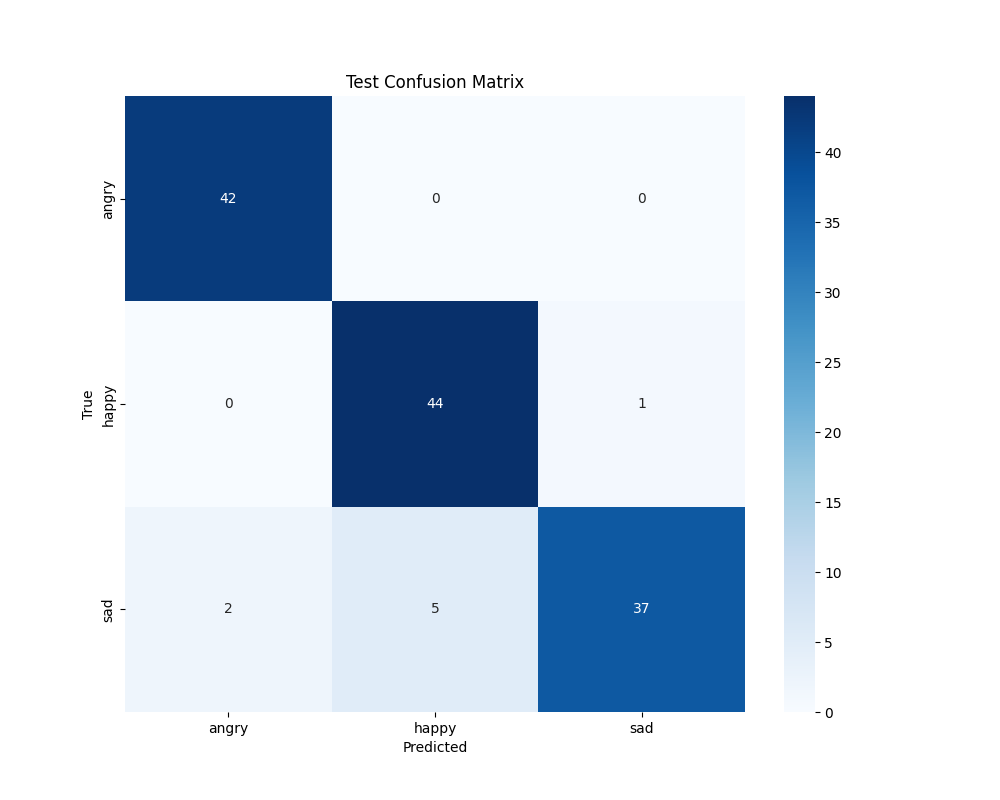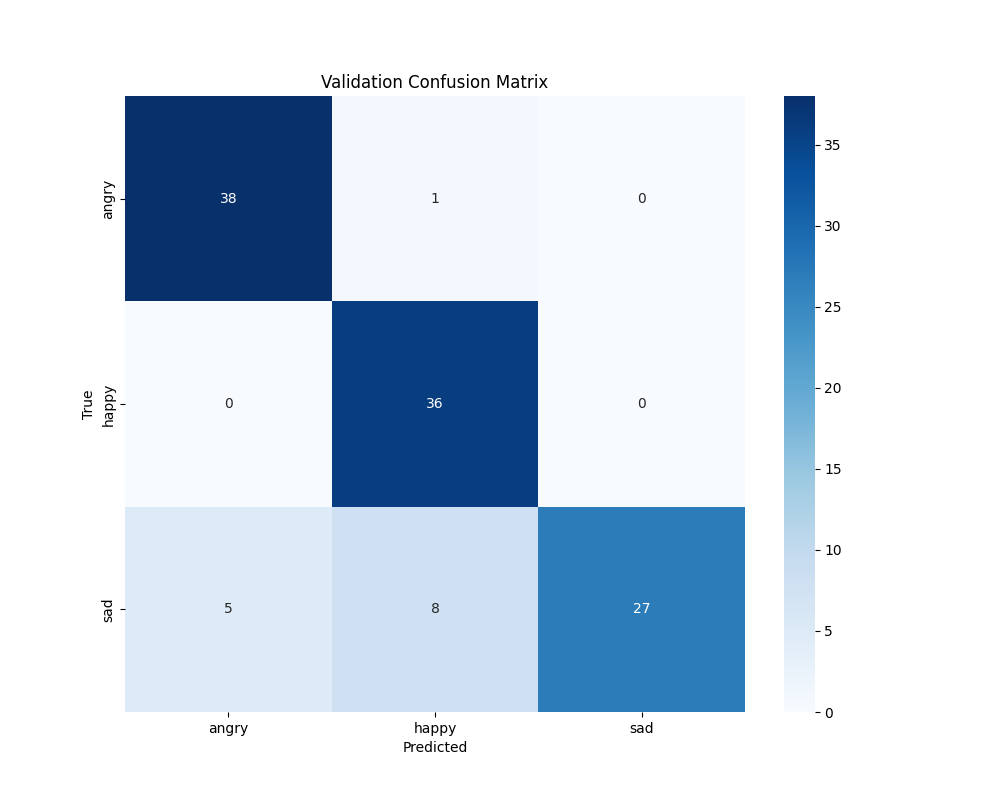

Training data (raw.zip) - https://drive.google.com/file/d/1VpdLojQWKeEvowg0XxrfEReQpl1pQazh/view?usp=drive_link

Testing data (test_raw.zip) - https://drive.google.com/file/d/1S9Nwpc-DuGKOq-Hl0U05N2TTlPrlY8f4/view?usp=drive_link